In [1]:
import numpy as np
from openfermion import QubitOperator, count_qubits, FermionOperator
import networkx as nx
import matplotlib.pyplot as plt
import math
import cirq


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  File "/Us

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  File "/Us

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  File "/Us

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/selm5534/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  File "/Us

AttributeError: _ARRAY_API not found

Build a Heisenberg Model Hamiltonian on a Graph

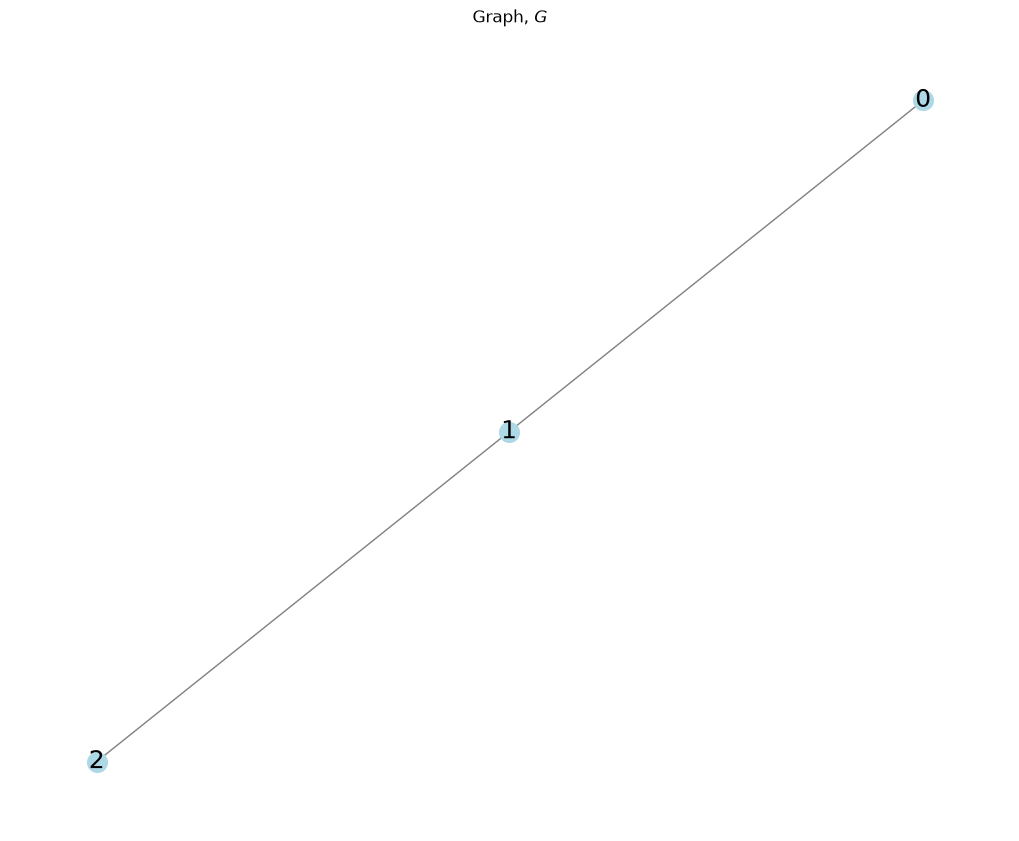

In [2]:
G = nx.Graph()
G.add_edges_from([(0, 1), (1, 2)])
# G = nx.grid_2d_graph(3,3)

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=39)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    edge_color="gray",
    node_size=200,
    font_size=18,
)
plt.title("Graph, $G$")
plt.axis("off")
plt.show()

In [3]:
def Heisenberg_graph(graph: nx.Graph, J: float, mu: float=0.0):
    hamiltonian = QubitOperator()
    for e in graph.edges:
        # Interaction terms for adjacent sites
        i = e[0]
        j = e[1]
        hamiltonian += QubitOperator(f'X{i} X{j}', J)
        hamiltonian += QubitOperator(f'Y{i} Y{j}', J)
        hamiltonian += QubitOperator(f'Z{i} Z{j}', J)
    
    for v in graph.nodes:
        hamiltonian += QubitOperator(f'Z{v}', mu)

    return hamiltonian


In [4]:
H_graph = Heisenberg_graph(G, 1,1.1)
H_graph

1.0 [X0 X1] +
1.0 [Y0 Y1] +
1.1 [Z0] +
1.0 [Z0 Z1] +
1.0 [X1 X2] +
1.0 [Y1 Y2] +
1.1 [Z1] +
1.0 [Z1 Z2] +
1.1 [Z2]

Boom Hamiltonians! Now let's block encode them with LCU

In [5]:
def Prepare_from_H_anc(
    Hamiltonian,
    ancilla_prefix: str = "ancilla",
    atol: float = 1e-10,
) -> tuple[cirq.Circuit, list[cirq.Qid]]:
    """
    Returns a Cirq circuit preparing

        sum_k sqrt(abs(c_k) / lambda) |k>

    where lambda = sum_k abs(c_k), and c_k are the Hamiltonian coefficients.

    If the number of terms is not a power of two, the weight vector is padded
    with zeros.

    Convention:
        ancilla_qubits[0] is the most significant bit of |k>.

    Args:
        Hamiltonian:
            Object with a .terms dictionary mapping terms to coefficients.

        ancilla_prefix:
            Prefix used to name the ancilla qubits. For example,
            ancilla_prefix="ancilla_w3" gives qubits

                ancilla_w3_0, ancilla_w3_1, ...

        atol:
            Numerical tolerance.
    """

    terms = list(Hamiltonian.terms.items())
    num_terms = len(terms)

    if num_terms == 0:
        raise ValueError("Hamiltonian has no terms.")

    num_ancillas = int(np.ceil(np.log2(num_terms)))

    ancilla_qubits = [
        cirq.NamedQubit(f"{ancilla_prefix}_{i}")
        for i in range(num_ancillas)
    ]

    coefficients = np.array(
        [coeff for _, coeff in terms],
        dtype=np.complex128,
    )

    weights = np.abs(coefficients)
    lam = float(np.sum(weights))

    if lam <= atol:
        raise ValueError("Hamiltonian has zero 1-norm.")

    padded_weights = np.zeros(2**num_ancillas, dtype=float)
    padded_weights[:num_terms] = weights

    circuit = cirq.Circuit()

    for depth in range(num_ancillas):
        target = ancilla_qubits[depth]

        block_size = 2 ** (num_ancillas - depth)
        half_block = block_size // 2

        for prefix in range(2**depth):
            start = prefix * block_size

            left_weight = float(
                np.sum(padded_weights[start : start + half_block])
            )
            right_weight = float(
                np.sum(padded_weights[start + half_block : start + block_size])
            )

            total = left_weight + right_weight

            if total <= atol:
                continue

            theta = 2.0 * math.atan2(
                math.sqrt(right_weight),
                math.sqrt(left_weight),
            )

            if abs(theta) <= atol:
                continue

            operation = cirq.ry(theta).on(target)

            if depth > 0:
                controls = ancilla_qubits[:depth]

                bits = [
                    (prefix >> (depth - 1 - j)) & 1
                    for j in range(depth)
                ]

                operation = operation.controlled_by(
                    *controls,
                    control_values=bits,
                )

            circuit.append(operation)

    return circuit, ancilla_qubits
PREP, ancilla_qubits = Prepare_from_H_anc(H_graph, "ancilla")

In [6]:
# 1. Initialize Cirq's simulator
simulator = cirq.Simulator()

# 2. Simulate the circuit you just built
result = simulator.simulate(PREP)

# 3. Get the final state vector
# We pass the exact ancilla_qubits to ensure the vector components map 
# to the standard binary order: |000>, |001>, |010>, etc.
# simulated_state = result.final_state_vector(qubit_order=ancilla_qubits)
simulated_state = result
print(simulated_state.final_state_vector)

[0.3279129 +0.j 0.3279129 +0.j 0.3279129 +0.j 0.3279129 +0.j
 0.3279129 +0.j 0.3279129 +0.j 0.34391797+0.j 0.34391797+0.j
 0.34391797+0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.        +0.j]


In [7]:
def split_terms_into_windows(Hamiltonian, num_windows: int):
    """
    Split Hamiltonian.terms into num_windows windows.
    """
    terms = list(Hamiltonian.terms.items())

    if num_windows < 1:
        raise ValueError("num_windows must be at least 1.")

    if num_windows > len(terms):
        raise ValueError("num_windows cannot exceed the number of Hamiltonian terms.")

    sizes = [len(terms) // num_windows] * num_windows

    for i in range(len(terms) % num_windows):
        sizes[i] += 1

    windows = []
    start = 0

    for size in sizes:
        stop = start + size
        windows.append(terms[start:stop])
        start = stop

    return windows


def sub_hamiltonian_from_terms(selected_terms):
    """
    Build an OpenFermion QubitOperator from a list of
    (pauli_term, coefficient) pairs.
    """
    H_sub = QubitOperator()

    for pauli_term, coeff in selected_terms:
        H_sub += QubitOperator(pauli_term, coeff)

    return H_sub

In [8]:
def SELECT_from_H(
    Hamiltonian,
    ancilla_prefix: str = "ancilla",
    target_prefix: str = "target",
    atol: float = 1e-9,
):
    terms = list(Hamiltonian.terms.items())
    num_terms = len(terms)

    if num_terms == 0:
        raise ValueError("Hamiltonian has no terms.")

    num_targets = count_qubits(Hamiltonian)
    num_ancillas = int(np.ceil(np.log2(num_terms)))

    ancilla_qubits = [
        cirq.NamedQubit(f"{ancilla_prefix}_{i}")
        for i in range(num_ancillas)
    ]

    target_qubits = [
        cirq.NamedQubit(f"{target_prefix}_{i}")
        for i in range(num_targets)
    ]

    circuit = cirq.Circuit()

    for idx, (pauli_term, _) in enumerate(terms):
        binary_str = format(idx, f"0{num_ancillas}b")
        control_values = [int(bit) for bit in binary_str]

        pauli_gates = []

        for qubit_idx, pauli_char in pauli_term:
            target = target_qubits[qubit_idx]

            if pauli_char == "X":
                pauli_gates.append(cirq.X(target))
            elif pauli_char == "Y":
                pauli_gates.append(cirq.Y(target))
            elif pauli_char == "Z":
                pauli_gates.append(cirq.Z(target))
            else:
                raise ValueError(f"Unknown Pauli character: {pauli_char}")

        for gate in pauli_gates:
            if num_ancillas == 0:
                circuit.append(gate)
            else:
                circuit.append(
                    gate.controlled_by(
                        *ancilla_qubits,
                        control_values=control_values,
                    )
                )

    return circuit, ancilla_qubits, target_qubits

In [9]:
SELECT, ancilla_qubits, target_quibits = SELECT_from_H(H_graph)

In [10]:
PREP_dagger = cirq.inverse(PREP)
circuit=cirq.Circuit()
circuit+=PREP
circuit+=SELECT
circuit+=PREP_dagger
circuit

ancilla_0: ───Ry(0.224π)───(0)──────────(0)────────(0)──────────(0)────────(0)────────(0)────────(0)────────(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────(0)─────────(0)─────────(0)─────────(0)─────────(0)───────────(0)─────────(0)───────────Ry(-0.224π)───
                           │            │          │            │          │          │          │          │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │           │             │           │
ancilla_1: ────────────────Ry(0.508π)───(0)────────@────────────(0)────────(0)────────@──────────@──────────(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────@─────@─────@─────@─────@─────(0)───@───────────@───────────(0)─────────(0)─────────@─────────────(0)─────────Ry(-0.508π)─────────────────
                                        │          │            │          │          │          │          │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │           │             │
ancilla_2: ─────────────────────────────Ry(0.5π)───Ry(0.515π)───(0)────────@──────────(0)────────@──────────(0)───(0)───(0)───(0)───@─────@─────@─────@─────(0)───(0)───(0)───(0)───@─────@─────(0)───@───────────(0)─────────@───────────(0)─────────Ry(-0.515π)───Ry(-0.5π)───────────────────────────────
                                                                │          │          │          │          │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │
ancilla_3: ─────────────────────────────────────────────────────Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───@─────(0)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)─────────────────────────────────────────────────────────
                                                                                                            │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
target_0: ──────────────────────────────────────────────────────────────────────────────────────────────────X─────┼─────Y─────┼─────Z─────┼─────┼─────┼─────┼─────┼─────┼─────┼─────Z─────┼─────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────
                                                                                                                  │           │           │     │     │     │     │     │     │           │     │
target_1: ────────────────────────────────────────────────────────────────────────────────────────────────────────X───────────Y───────────Z─────X─────┼─────Y─────┼─────Z─────┼───────────Z─────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────
                                                                                                                                                      │           │           │                 │
target_2: ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────X───────────Y───────────Z─────────────────Z───────────────────────────────────────────────────────────────────────────────────────────────────────────

In [11]:
# 1. Initialize Cirq's simulator
simulator2 = cirq.Simulator()

# 2. Simulate the circuit you just built
result2 = simulator2.simulate(circuit)

# 3. Get the final state vector
# We pass the exact ancilla_qubits to ensure the vector components map 
# to the standard binary order: |000>, |001>, |010>, etc.
# simulated_state = result.final_state_vector(qubit_order=ancilla_qubits)
simulated_state2 = result2
simulated_state2.final_state_vector

array([ 5.6989253e-01+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j,  2.1505378e-01+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j, -2.1505378e-01+0.j,
        0.0000000e+00+0.j,  2.2030208e-01+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j,  2.2030205e-01+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
       -2.2030205e-01+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
       -5.2482528e-03+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
        2.1505378e-01+0.j,  0.0000000e+00+0.j,  2.2561133e-01+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j, -2.1511777e-01+0.j,
        0.0000000e+00+0.j,  0.0000000e+00+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j,  2.1511777e-01+0.j,  0.0000000e+00+0.j,
        0.0000000e+00+0.j, -5.2467766e-03+0.j,  0.0000000e+00+

In [12]:
def multi_controlled_Z(qubits: list[cirq.Qid]) -> cirq.Operation:
    """
    Returns a C^{n-1} Z gate on the given n-qubit register.

    It applies -1 to |11...1> and +1 to all other basis states.

    Convention:
        controls = qubits[:-1]
        target   = qubits[-1]
    """
    if len(qubits) == 0:
        raise ValueError("Need at least one qubit.")

    if len(qubits) == 1:
        return cirq.Z(qubits[0])

    controls = qubits[:-1]
    target = qubits[-1]

    return cirq.Z(target).controlled_by(*controls)

In [13]:
def build_RL_Operator(
    Hamiltonian,
    ancilla_prefix: str = "ancilla",
    atol: float = 1e-9,
):
    PREP, ancilla_qubits = Prepare_from_H_anc(
        Hamiltonian,
        ancilla_prefix=ancilla_prefix,
        atol=atol)

    PREP_dg = cirq.inverse(PREP)

    R_L = cirq.Circuit()
    R_L += PREP_dg
    # now because the paper says a controlled-Z on the zero state we need to apply X to all but one of the 
    R_L.append(cirq.X.on_each(*ancilla_qubits[:len(ancilla_qubits)-1]))
    R_L += multi_controlled_Z(ancilla_qubits)
    R_L.append(cirq.X.on_each(*ancilla_qubits[:len(ancilla_qubits)-1]))
    R_L += PREP

    return R_L, ancilla_qubits
RL,A=build_RL_Operator(H_graph)
RL

ancilla_0: ───(0)─────────(0)─────────(0)─────────(0)─────────(0)───────────(0)─────────(0)───────────Ry(-0.224π)───X───@───X───Ry(0.224π)───(0)──────────(0)────────(0)──────────(0)────────(0)────────(0)────────(0)────────
              │           │           │           │           │             │           │                               │                    │            │          │            │          │          │          │
ancilla_1: ───@───────────@───────────(0)─────────(0)─────────@─────────────(0)─────────Ry(-0.508π)───X─────────────────@───X────────────────Ry(0.508π)───(0)────────@────────────(0)────────(0)────────@──────────@──────────
              │           │           │           │           │             │                                           │                                 │          │            │          │          │          │
ancilla_2: ───@───────────(0)─────────@───────────(0)─────────Ry(-0.515π)───Ry(-0.5π)───X───────────────────────────────@───X─────────────────────────────Ry(0.5π)───Ry(0.515π)───(0)────────@──────────(0)────────@──────────
              │           │           │           │                                                                     │                                                         │          │          │          │
ancilla_3: ───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)─────────────────────────────────────────────────────────────Z─────────────────────────────────────────────────────────Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───

In [14]:
def build_walk_Operator(
    Hamiltonian,
    ancilla_prefix: str = "ancilla",
    target_prefix: str = "target",
    atol: float = 1e-9
):
    R_L, ancilla_qubits = build_RL_Operator(
        Hamiltonian,
        ancilla_prefix=ancilla_prefix,
        atol=atol
    )

    SELECT, ancilla_qubits, target_qubits = SELECT_from_H(
        Hamiltonian,
        ancilla_prefix=ancilla_prefix,
        target_prefix=target_prefix,
    )

    WALK = cirq.Circuit()
    WALK += SELECT
    WALK += R_L

    return WALK, ancilla_qubits, target_qubits
WALK, ancilla_qubits, target_qubits = build_walk_Operator(H_graph)
WALK

ancilla_0: ───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────(0)─────────(0)─────────(0)─────────(0)─────────(0)───────────(0)─────────(0)───────────Ry(-0.224π)───X───@───X───Ry(0.224π)───(0)──────────(0)────────(0)──────────(0)────────(0)────────(0)────────(0)────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │           │             │           │                               │                    │            │          │            │          │          │          │
ancilla_1: ───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────@─────@─────@─────@─────@─────(0)───@───────────@───────────(0)─────────(0)─────────@─────────────(0)─────────Ry(-0.508π)───X─────────────────@───X────────────────Ry(0.508π)───(0)────────@────────────(0)────────(0)────────@──────────@──────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │           │             │                                           │                                 │          │            │          │          │          │
ancilla_2: ───(0)───(0)───(0)───(0)───@─────@─────@─────@─────(0)───(0)───(0)───(0)───@─────@─────(0)───@───────────(0)─────────@───────────(0)─────────Ry(-0.515π)───Ry(-0.5π)───X───────────────────────────────@───X─────────────────────────────Ry(0.5π)───Ry(0.515π)───(0)────────@──────────(0)────────@──────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │                                                                     │                                                         │          │          │          │
ancilla_3: ───(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───@─────(0)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)─────────────────────────────────────────────────────────────Z─────────────────────────────────────────────────────────Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
target_0: ────X─────┼─────Y─────┼─────Z─────┼─────┼─────┼─────┼─────┼─────┼─────┼─────Z─────┼─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                    │           │           │     │     │     │     │     │     │           │     │
target_1: ──────────X───────────Y───────────Z─────X─────┼─────Y─────┼─────Z─────┼───────────Z─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                                                        │           │           │                 │
target_2: ──────────────────────────────────────────────X───────────Y───────────Z─────────────────Z─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [15]:
def controlled_SELECT_from_H(
    Hamiltonian,
    control_qubit: cirq.Qid,
    ancilla_prefix: str = "ancilla",
    target_prefix: str = "target",
    atol: float = 1e-9,
):
    terms = list(Hamiltonian.terms.items())
    num_terms = len(terms)

    if num_terms == 0:
        raise ValueError("Hamiltonian has no terms.")

    num_targets = count_qubits(Hamiltonian)
    num_ancillas = int(np.ceil(np.log2(num_terms)))

    ancilla_qubits = [
        cirq.NamedQubit(f"{ancilla_prefix}_{i}")
        for i in range(num_ancillas)
    ]

    target_qubits = [
        cirq.NamedQubit(f"{target_prefix}_{i}")
        for i in range(num_targets)
    ]

    circuit = cirq.Circuit()

    for idx, (pauli_term, _) in enumerate(terms):
        binary_str = format(idx, f"0{num_ancillas}b")
        ancilla_control_values = [int(bit) for bit in binary_str]

        all_controls = [control_qubit] + ancilla_qubits
        all_control_values = [1] + ancilla_control_values

        for qubit_idx, pauli_char in pauli_term:
            target = target_qubits[qubit_idx]

            if pauli_char == "X":
                gate = cirq.X(target)
            elif pauli_char == "Y":
                gate = cirq.Y(target)
            elif pauli_char == "Z":
                gate = cirq.Z(target)
            else:
                raise ValueError(f"Unknown Pauli character: {pauli_char}")

            circuit.append(
                gate.controlled_by(
                    *all_controls,
                    control_values=all_control_values,
                )
            )

    return circuit, ancilla_qubits, target_qubits, control_qubit
control_SELECT, ancilla_qubits, target_qubits, control_qubit = controlled_SELECT_from_H(H_graph, cirq.NamedQubit("readout"))
control_SELECT

ancilla_0: ───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
ancilla_1: ───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────@─────@─────@─────@─────@─────(0)───
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
ancilla_2: ───(0)───(0)───(0)───(0)───@─────@─────@─────@─────(0)───(0)───(0)───(0)───@─────@─────(0)───
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
ancilla_3: ───(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───@─────(0)───
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
readout: ─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
target_0: ────X─────┼─────Y─────┼─────Z─────┼─────┼─────┼─────┼─────┼─────┼─────┼─────Z─────┼─────┼─────
                    │           │           │     │     │     │     │     │     │           │     │
target_1: ──────────X───────────Y───────────Z─────X─────┼─────Y─────┼─────Z─────┼───────────Z─────┼─────
                                                        │           │           │                 │
target_2: ──────────────────────────────────────────────X───────────Y───────────Z─────────────────Z─────

In [16]:
def build_controlled_RL_Operator(
    Hamiltonian,
    control_qubit: cirq.Qid,
    ancilla_prefix: str = "ancilla",
    atol: float = 1e-9,
):
    PREP, ancilla_qubits = Prepare_from_H_anc(
        Hamiltonian,
        ancilla_prefix=ancilla_prefix,
    )

    PREP_dg = cirq.inverse(PREP)

    control_R_L = cirq.Circuit()

    control_R_L += PREP_dg

    # This Z fixes the conditional global minus sign.
    # Without it, the branch control_qubit=1 gets -R_L instead of R_L.
    control_R_L.append(cirq.Z(control_qubit))

    control_R_L.append(cirq.X.on_each(*ancilla_qubits))
    control_R_L += multi_controlled_Z(ancilla_qubits + [control_qubit])
    control_R_L.append(cirq.X.on_each(*ancilla_qubits))

    control_R_L += PREP

    return control_R_L, ancilla_qubits, control_qubit

In [17]:
def build_control_walk_Operator(
    Hamiltonian,
    control_qubit: cirq.Qid,
    ancilla_prefix: str = "ancilla",
    target_prefix: str = "target",
):
    control_SELECT, ancilla_qubits, target_qubits, _ = controlled_SELECT_from_H(
        Hamiltonian,
        control_qubit,
        ancilla_prefix=ancilla_prefix,
        target_prefix=target_prefix,
    )

    control_R_L, ancilla_qubits, _ = build_controlled_RL_Operator(
        Hamiltonian,
        control_qubit,
        ancilla_prefix=ancilla_prefix,
    )

    control_WALK = cirq.Circuit()
    control_WALK += control_SELECT
    control_WALK += control_R_L

    return control_WALK, ancilla_qubits, target_qubits, control_qubit
control_WALK, ancilla_qubits, target_qubits, control_qubit = build_control_walk_Operator(H_graph, cirq.NamedQubit("readout"))
control_WALK

ancilla_0: ───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────(0)─────────(0)─────────(0)─────────(0)─────────(0)───────────(0)─────────(0)───────────Ry(-0.224π)───X───@───X───Ry(0.224π)───(0)──────────(0)────────(0)──────────(0)────────(0)────────(0)────────(0)────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │           │             │           │                               │                    │            │          │            │          │          │          │
ancilla_1: ───(0)───(0)───(0)───(0)───(0)───(0)───(0)───(0)───@─────@─────@─────@─────@─────@─────(0)───@───────────@───────────(0)─────────(0)─────────@─────────────(0)─────────Ry(-0.508π)───X─────────────────@───X────────────────Ry(0.508π)───(0)────────@────────────(0)────────(0)────────@──────────@──────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │           │             │                                           │                                 │          │            │          │          │          │
ancilla_2: ───(0)───(0)───(0)───(0)───@─────@─────@─────@─────(0)───(0)───(0)───(0)───@─────@─────(0)───@───────────(0)─────────@───────────(0)─────────Ry(-0.515π)───Ry(-0.5π)───X───────────────────────────────@───X─────────────────────────────Ry(0.5π)───Ry(0.515π)───(0)────────@──────────(0)────────@──────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │     │           │           │           │                                                                     │                                                         │          │          │          │
ancilla_3: ───(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───(0)───@─────@─────(0)───@─────(0)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)───Ry(-0.5π)───X─────────────────────────────────────────────────────────@───X─────────────────────────────────────────────────────Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───Ry(0.5π)───
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │                                                                                                               │
readout: ─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────@─────Z─────────────────────────────────────────────────────────────────────────────────────────────────────────Z─────────────────────────────────────────────────────────────────────────────────────────────────────
              │     │     │     │     │     │     │     │     │     │     │     │     │     │     │
target_0: ────X─────┼─────Y─────┼─────Z─────┼─────┼─────┼─────┼─────┼─────┼─────┼─────Z─────┼─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                    │           │           │     │     │     │     │     │     │           │     │
target_1: ──────────X───────────Y───────────Z─────X─────┼─────Y─────┼─────Z─────┼───────────Z─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                                                        │           │           │                 │
target_2: ──────────────────────────────────────────────X───────────Y───────────Z─────────────────Z─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [18]:
def Prepare_sine_state_readout(
    read_out: list[cirq.Qid],
    atol: float = 1e-12,
) -> cirq.Circuit:
    """
    Prepares the sine state on the read_out register:

        sqrt(2 / (2^m + 1))
        sum_{n=0}^{2^m - 1}
            sin(pi (n + 1) / (2^m + 1)) |n>

    Convention:
        read_out[0] is the most significant bit of |n>.
    """

    m = len(read_out)

    if m == 0:
        return cirq.Circuit()

    dim = 2**m

    weights = np.array(
        [
            math.sin(math.pi * (n + 1) / (dim + 1)) ** 2
            for n in range(dim)
        ],
        dtype=float,
    )

    circuit = cirq.Circuit()

    for depth in range(m):
        target = read_out[depth]

        block_size = 2 ** (m - depth)
        half_block = block_size // 2

        for prefix in range(2**depth):
            start = prefix * block_size

            left_weight = float(
                np.sum(weights[start : start + half_block])
            )
            right_weight = float(
                np.sum(weights[start + half_block : start + block_size])
            )

            total = left_weight + right_weight

            if total <= atol:
                continue

            theta = 2.0 * math.atan2(
                math.sqrt(right_weight),
                math.sqrt(left_weight),
            )

            if abs(theta) <= atol:
                continue

            operation = cirq.ry(theta).on(target)

            if depth > 0:
                controls = read_out[:depth]

                bits = [
                    (prefix >> (depth - 1 - j)) & 1
                    for j in range(depth)
                ]

                operation = operation.controlled_by(
                    *controls,
                    control_values=bits,
                )

            circuit.append(operation)

    return circuit

In [19]:
m = 4
read_out = [cirq.NamedQubit(f"read_out_{i}") for i in range(m)]

Chi_m = Prepare_sine_state_readout(read_out)

Chi_m

read_out_0: ───Ry(0.5π)───(0)──────────@────────────(0)──────────(0)──────────@────────────@────────────(0)────────(0)──────────(0)──────────(0)──────────@────────────@────────────@────────────@──────────
                          │            │            │            │            │            │            │          │            │            │            │            │            │            │
read_out_1: ──────────────Ry(0.696π)───Ry(0.304π)───(0)──────────@────────────(0)──────────@────────────(0)────────(0)──────────@────────────@────────────(0)──────────(0)──────────@────────────@──────────
                                                    │            │            │            │            │          │            │            │            │            │            │            │
read_out_2: ────────────────────────────────────────Ry(0.718π)───Ry(0.546π)───Ry(0.454π)───Ry(0.282π)───(0)────────@────────────(0)──────────@────────────(0)──────────@────────────(0)──────────@──────────
                                                                                                        │          │            │            │            │            │            │            │
read_out_3: ────────────────────────────────────────────────────────────────────────────────────────────Ry(0.7π)───Ry(0.578π)───Ry(0.536π)───Ry(0.511π)───Ry(0.489π)───Ry(0.464π)───Ry(0.422π)───Ry(0.3π)───

In [20]:
# 1. Initialize Cirq's simulator
simulator2 = cirq.Simulator()

# 2. Simulate the circuit you just built
result2 = simulator2.simulate(Chi_m)

# 3. Get the final state vector
# We pass the exact ancilla_qubits to ensure the vector components map 
# to the standard binary order: |000>, |001>, |010>, etc.
# simulated_state = result.final_state_vector(qubit_order=ancilla_qubits)
simulated_state2 = result2
simulated_state2.final_state_vector

array([0.06302557+0.j, 0.12390488+0.j, 0.18056475+0.j, 0.2310757 +0.j,
       0.27371764+0.j, 0.30703846+0.j, 0.32990345+0.j, 0.341534  +0.j,
       0.341534  +0.j, 0.32990345+0.j, 0.30703846+0.j, 0.27371764+0.j,
       0.2310757 +0.j, 0.18056475+0.j, 0.12390488+0.j, 0.06302557+0.j],
      dtype=complex64)

In [21]:
def append_power(circuit: cirq.Circuit, block: cirq.Circuit, power: int):
    if power < 0:
        raise ValueError("power must be nonnegative")

    for _ in range(power):
        circuit += block


def build_outer_loop_circuit(
    Hamiltonian,
    m: int,
    atol: float = 1e-10,
):
    """
    Builds the unwindowed outer loop for the QPE circuit:

        chi_m on read_out,
        PREP on 
        controlled-W on read_out[0],
        then for j = 1,...,m-1:

            controlled-R_L on read_out[j],
            W^{2^{j-1}},
            controlled-R_L on read_out[j].

    Uses the functions already defined in your notebook:

        Prepare_sine_state_readout
        build_walk_Operator
        build_control_walk_Operator
        build_controlled_RL_Operator

    Convention:
        read_out[0] is the top readout wire.
    """

    if m < 1:
        raise ValueError("m must be at least 1.")

    read_out = [
        cirq.NamedQubit(f"read_out_{j}")
        for j in range(m)
    ]

    circuit = cirq.Circuit()

    # Prepare chi_m on the readout register.
    Chi_m = Prepare_sine_state_readout(read_out, atol)
    circuit += Chi_m
    
    # Prepare ancilla register
    PREP, ancilla_qubits = Prepare_from_H_anc(H_graph, "ancilla")
    circuit+=PREP

    # Build the un-controlled walk block.
    WALK, ancilla_qubits, target_qubits = build_walk_Operator(Hamiltonian)

    # First solid-control W block, controlled on read_out[0].
    control_WALK, ancilla_qubits, target_qubits, _ = build_control_walk_Operator(
        Hamiltonian,
        read_out[0],
    )
    circuit += control_WALK

    # Remaining open-control R_L W^{power} R_L blocks.
    for j in range(1, m):
        control_qubit = read_out[j]
        power = 2 ** (j - 1)

        control_RL, ancilla_qubits, _, = build_controlled_RL_Operator(
            Hamiltonian,
            control_qubit,
        )

        circuit += control_RL
        append_power(circuit, WALK, power)
        circuit += control_RL
    
    # Inverse QFT on the same fixed read_out register.
    circuit += cirq.inverse(cirq.qft(*read_out))

    registers = {
        "read_out": read_out,
        "ancilla_qubits": ancilla_qubits,
        "target_qubits": target_qubits,
    }

    return circuit, registers

In [22]:
def build_outer_loop_windowed_parallel(
    Hamiltonian,
    m: int, 
    num_windows: int,
    target_prefix: str = "target",
    rl_powers: list[int] | None = None,
    atol: float = 1e-10,
):
    read_out = [
        cirq.NamedQubit(f"read_out_{j}")
        for j in range(m)
    ]

    # This is the order used by chi_m and QFT:
    # phase_qubits[0] is MSB.
    #
    # The outer-loop powers use read_out[0] as the power-1 / LSB qubit,
    # so phase_qubits is the reversed list.
    phase_qubits = read_out[::-1]

    if m < 1:
        raise ValueError("read_out must contain at least one qubit.")

    if num_windows < 1:
        raise ValueError("num_windows must be at least 1.")

    if rl_powers is None:
        # Keep this unshifted:
        # read_out[1] gets W^1,
        # read_out[2] gets W^2,
        # read_out[3] gets W^4,
        # etc.
        rl_powers = [2**j for j in range(m - 1)]

    if len(rl_powers) != m - 1:
        raise ValueError("rl_powers must have length m - 1.")

    term_windows = split_terms_into_windows(
        Hamiltonian,
        num_windows=num_windows,
    )

    sub_Hamiltonians = [
        sub_hamiltonian_from_terms(selected_terms)
        for selected_terms in term_windows
    ]

    circuit = cirq.Circuit()

    window_ancillas = [None for _ in range(num_windows)]
    target_qubits = None

    # 1. Prepare chi_m in MSB order.
    circuit += Prepare_sine_state_readout(phase_qubits, atol=atol)
    
    # 1b. Prepare ancilla in \ket{\mc{L}}
    initial_ancilla_prep = cirq.Circuit()

    for w, H_sub in enumerate(sub_Hamiltonians):
        Prep_w, ancilla_w = Prepare_from_H_anc(
            H_sub,
            ancilla_prefix=f"ancilla_w{w}",
        )
        initial_ancilla_prep += Prep_w
    
    circuit +=initial_ancilla_prep
    # 2. First block: controlled-W, controlled by read_out[0].
    control_qubit = read_out[0]

    for w, H_sub in enumerate(sub_Hamiltonians):
        ancilla_prefix = f"ancilla_w{w}"

        control_W_w, ancilla_w, target_qubits_w, _ = build_control_walk_Operator(
            H_sub,
            control_qubit=control_qubit,
            ancilla_prefix=ancilla_prefix,
            target_prefix=target_prefix,
        )

        window_ancillas[w] = ancilla_w

        if target_qubits is None:
            target_qubits = target_qubits_w

        circuit += control_W_w

    # 3. Remaining R_L W^k R_L blocks.
    for j in range(1, m):
        control_qubit = read_out[j]
        power = rl_powers[j - 1]

        # Left controlled-R_L.
        for w, H_sub in enumerate(sub_Hamiltonians):
            ancilla_prefix = f"ancilla_w{w}"

            control_RL_w, ancilla_w, _ = build_controlled_RL_Operator(
                H_sub,
                control_qubit=control_qubit,
                ancilla_prefix=ancilla_prefix,
            )

            if window_ancillas[w] is None:
                window_ancillas[w] = ancilla_w

            circuit += control_RL_w

        # Middle W^power.
        for _ in range(power):
            for w, H_sub in enumerate(sub_Hamiltonians):
                ancilla_prefix = f"ancilla_w{w}"

                W_w, ancilla_w, target_qubits_w = build_walk_Operator(
                    H_sub,
                    ancilla_prefix=ancilla_prefix,
                    target_prefix=target_prefix,
                )

                if window_ancillas[w] is None:
                    window_ancillas[w] = ancilla_w

                if target_qubits is None:
                    target_qubits = target_qubits_w

                circuit += W_w

        # Right controlled-R_L.
        for w, H_sub in enumerate(sub_Hamiltonians):
            ancilla_prefix = f"ancilla_w{w}"

            control_RL_w, ancilla_w, _ = build_controlled_RL_Operator(
                H_sub,
                control_qubit=control_qubit,
                ancilla_prefix=ancilla_prefix,
            )

            if window_ancillas[w] is None:
                window_ancillas[w] = ancilla_w

            circuit += control_RL_w

    # 4. Inverse QFT in MSB order.
    circuit += cirq.inverse(cirq.qft(*phase_qubits))

    all_ancillas = [
        q
        for ancilla_register in window_ancillas
        for q in ancilla_register
    ]

    registers = {
        "read_out": read_out,
        "phase_qubits": phase_qubits,
        "window_ancillas": window_ancillas,
        "all_ancillas": all_ancillas,
    }
    info = {
        "target_qubits": target_qubits,
        "sub_Hamiltonians": sub_Hamiltonians,
        "term_windows": term_windows,
        "num_windows": num_windows,
        "rl_powers": rl_powers,
    }

    return circuit, registers, info

In [23]:
import math
import numpy as np
import cirq
from collections import Counter
from openfermion import QubitOperator


def hamiltonian_l1_norm(Hamiltonian) -> float:
    return float(sum(abs(c) for c in Hamiltonian.terms.values()))


def prepare_positive_eigenstate_aX_plus_bZ(
    target_qubit: cirq.Qid,
    a: float,
    b: float,
) -> cirq.Circuit:
    """
    Prepares the + eigenstate of H = a X + b Z.

    The exact positive eigenvalue is sqrt(a^2 + b^2).
    """
    theta = math.atan2(a, b)
    return cirq.Circuit(cirq.ry(theta).on(target_qubit))


def bits_to_int_msb(bits: np.ndarray) -> np.ndarray:
    """
    Interpret bits[:, 0] as the most significant bit.
    """
    m = bits.shape[1]
    weights = 2 ** np.arange(m - 1, -1, -1)
    return bits @ weights


def bits_to_int_lsb(bits: np.ndarray) -> np.ndarray:
    """
    Interpret bits[:, 0] as the least significant bit.
    """
    m = bits.shape[1]
    weights = 2 ** np.arange(0, m)
    return bits @ weights


def bit_reverse_int(y: int, m: int) -> int:
    return int(format(y, f"0{m}b")[::-1], 2)


def summarize_outerloop_qpe_result_bit_reversed(
    result,
    lam: float,
    exact_energy: float | None = None,
    key: str = "phase",
    top: int = 12,
):
    bits = result.measurements[key]
    m = bits.shape[1]

    # First read the bits in the order Cirq returned them.
    weights = 2 ** np.arange(m - 1, -1, -1)
    ys_raw = bits @ weights

    # Then bit-reverse the integer.
    ys = np.array([bit_reverse_int(int(y), m) for y in ys_raw])

    counts = Counter(ys)

    print("Measurement shape:", bits.shape)
    print("\nBit-reversed walk-phase decoder")
    print("bits        y_raw  y_rev  shots    phase        folded      energy")

    shot_energies = []

    for y in ys:
        phase = y / 2**m
        folded_phase = min(phase, 1.0 - phase)
        energy = lam * math.cos(2 * math.pi * folded_phase)
        shot_energies.append(energy)

    shot_energies = np.array(shot_energies)

    raw_counts = Counter(ys_raw)

    for y_rev, count in counts.most_common(top):
        phase = y_rev / 2**m
        folded_phase = min(phase, 1.0 - phase)
        energy = lam * math.cos(2 * math.pi * folded_phase)

        # Find one raw integer that reverses to this y_rev.
        y_raw = bit_reverse_int(int(y_rev), m)

        bitstring_raw = format(y_raw, f"0{m}b")

        print(
            f"{bitstring_raw}  {y_raw:5d}  {y_rev:5d}  {count:7d}  "
            f"{phase: .6f}  {folded_phase: .6f}  {energy: .8f}"
        )

    dominant_y, _ = counts.most_common(1)[0]
    dominant_phase = dominant_y / 2**m
    dominant_folded_phase = min(dominant_phase, 1.0 - dominant_phase)
    dominant_energy = lam * math.cos(2 * math.pi * dominant_folded_phase)

    print("\nMean decoded energy over all shots:", float(np.mean(np.abs(shot_energies))))
    print("Median decoded energy over all shots:", float(np.median(shot_energies)))
    print("Dominant decoded energy:", dominant_energy)

    if exact_energy is not None:
        print("Exact energy:", exact_energy)
        print("Mean absolute error:", abs(np.mean(np.abs(shot_energies)) - exact_energy))

    return shot_energies, counts

In [24]:
m = 5
num_windows = 3

outer_loop, regs,info = build_outer_loop_windowed_parallel(
    H_graph,
    m,
    num_windows=num_windows,
    target_prefix="target",
)

outer_loop

ancilla_w0_0: ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────Ry(0.392π)───(0)────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)───(0)───(0)───(0)───@─────@─────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────(0)─────────Ry(-0.392π)───X───@───X───Ry(0.392π)───(0)────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [25]:
# ------------------------------------------------------------
# Small exactly-solvable test Hamiltonian
# ------------------------------------------------------------
#
# H = a X + b Z
#
# Eigenvalues are ±sqrt(a^2 + b^2).
#
# Important: a and b are positive here, so this matches your current
# SELECT convention if your SELECT ignores coefficient signs/phases.

a = 0.9
b = 0.5

H_test = QubitOperator("X0", a) + QubitOperator("Z0", b)

lam = hamiltonian_l1_norm(H_test)
exact_positive_energy = math.sqrt(a**2 + b**2)

print("lambda =", lam)
print("exact positive energy =", exact_positive_energy)
print("exact E/lambda =", exact_positive_energy / lam)
print("exact theta =", math.acos(exact_positive_energy / lam))

lambda = 1.4
exact positive energy = 1.0295630140987
exact E/lambda = 0.7354021529276429
exact theta = 0.7445363677986948


In [26]:
# ------------------------------------------------------------
# Build your outer-loop circuit
# ------------------------------------------------------------

m = 9
num_windows = 1

outer_loop, regs,info = build_outer_loop_windowed_parallel(
    H_test,
    m=m,
    num_windows=num_windows,
    target_prefix="target",
)

read_out = regs["read_out"]

# For this tiny Hamiltonian there is one system qubit.
# If your registers already contain target_qubits, use them.
if "target_qubits" in regs and regs["target_qubits"] is not None:
    target_qubits = regs["target_qubits"]
else:
    target_qubits = [cirq.NamedQubit("target_0")]

target_state_prep = prepare_positive_eigenstate_aX_plus_bZ(
    target_qubits[0],
    a=a,
    b=b,
)

In [27]:
# ------------------------------------------------------------
# Full circuit:
#
#   prepare target eigenstate
#   prepare window ancillas
#   apply your outer loop
#   measure read_out
# ------------------------------------------------------------

test_circuit = cirq.Circuit()
test_circuit += target_state_prep
test_circuit += outer_loop
test_circuit.append(cirq.measure(*read_out, key="phase"))

test_circuit

ancilla_w0_0: ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [28]:
from numpy.polynomial.chebyshev import chebinterpolate
from qsppack.solver import solve


def hamiltonian_l1_norm(Hamiltonian) -> float:
    """
    lambda = sum_k |c_k| for H = sum_k c_k P_k.
    """
    coeffs = list(Hamiltonian.terms.values())
    lam = float(np.sum(np.abs(coeffs)))

    if lam <= 0:
        raise ValueError("Hamiltonian has zero LCU 1-norm.")

    return lam

In [29]:
simulator = cirq.Simulator()

result = simulator.run(
    test_circuit,
    repetitions=1500,
)

shot_energies, counts = summarize_outerloop_qpe_result_bit_reversed(
    result,
    lam=lam,
    exact_energy=exact_positive_energy,
    key="phase",
    top=12,
)

Measurement shape: (1500, 9)

Bit-reversed walk-phase decoder
bits        y_raw  y_rev  shots    phase        folded      energy
101111000    376     61      270   0.119141   0.119141   1.02571598
110000111    391    451      260   0.880859   0.119141   1.02571598
110000110    390    195      239   0.380859   0.380859  -1.02571598
101111001    377    317      223   0.619141   0.380859  -1.02571598
001000111     71    452      146   0.882812   0.117188   1.03733158
001111000    120     60      122   0.117188   0.117188   1.03733158
001000110     70    196      121   0.382812   0.382812  -1.03733158
001111001    121    316      104   0.617188   0.382812  -1.03733158
010000111    135    450        4   0.878906   0.121094   1.01394592
010000110    134    194        2   0.378906   0.378906  -1.01394592
101000110    326    197        2   0.384766   0.384766  -1.04879095
101000111    327    453        2   0.884766   0.115234   1.04879095

Mean decoded energy over all shots: 1.0295850476292465

In [30]:
info

{'target_qubits': [cirq.NamedQubit('target_0')],
 'sub_Hamiltonians': [0.9 [X0] +
  0.5 [Z0]],
 'term_windows': [[(((0, 'X'),), 0.9), (((0, 'Z'),), 0.5)]],
 'num_windows': 1,
 'rl_powers': [1, 2, 4, 8, 16, 32, 64, 128]}